# 单晶铜热膨胀行为及线膨胀系数的分子动力学研究

小组成员：【请填写姓名及实际分工】

计算材料学课程项目。本文由原始计算数据生成；研究定位为方法复现与势函数适用性评价。

## 摘要

采用LAMMPS和Mishin等人2001年铜EAM1势，对三向周期性FCC铜进行近零外压NPT分子动力学模拟，研究300–800 K的晶格常数与体积。设置6个温度、每点3次独立重复，并在温区端点检查尺寸、时间步与时长。实验参考采用NIST SRM 736的1990修订表，统一以300 K长度为参考。

计算结果：温区平均线膨胀系数为 **17.8883 ×10⁻⁶ K⁻¹**，95%统计区间半宽为0.0151 ×10⁻⁶ K⁻¹；NIST同定义参考为18.6038 ×10⁻⁶ K⁻¹，相对偏差-3.85%。尺寸、时间步和时长三项检查全部满足预设实用阈值。统计区间不包括模型误差。

## 1. 研究背景与文献比较

铜受热后的平均原子位置间距增加，反映势能的非谐性。谐振动模型本身不能给出普通热膨胀。NPT允许体积随温度调整，适合获得近零外压的平衡晶格参数。

Alper与Politzer（1999）以及Kazanc等（2006）展示经验势有限温度研究；Narasimhan与de Gironcoli（2002）、Rudin等（2002）采用电子结构与准谐自由能路线。Lysogorskiy等（2021）直接比较铜的多类势；Olsson等（2023）用Mishin势研究单晶及晶界影响。它们支持本项目路线，但不能据此宣称我们已获得相同精度。

本项目保留原选题的Mishin EAM1，不额外开展机器学习势或DFT计算。详细的25项来源、阅读证据和方法对比见 [文献调研](docs/literature_review.md)。

## 2. 模型与计算方法

FCC常规晶胞沿[100]、[010]、[001]排列，10×10×10晶胞共4000原子，三向周期性边界，无自由表面和晶界。初始a=3.615 Å，先做原子和晶胞能量最小化。Cu质量63.546 u。势文件为NIST `Cu01.eam.alloy`，调用`eam/alloy`；来源与哈希见potentials/SOURCE.md。

使用metal单位制：长度Å、时间ps、能量eV、压力bar。NPT设温300、400、500、600、700、800 K，外压0 bar，等比例调整盒长；时间步0.001 ps（1 fs），温度阻尼0.1 ps，压力阻尼1 ps。每点200 ps平衡、500 ps采样，间隔0.1 ps输出未作长时间平均的标量，结构每100 ps输出。

3个重复的种子基数为13579、24681、97531，实际种子=基数+19×温度，每个温度独立初始化。端点各增加12³晶胞、0.5 fs步长和1 ns平衡+1 ns采样三项检查，总计24条轨迹。所有具体参数见run_study.py及outputs/study_manifest.json。

### 2.1 数据处理

每帧由a=Lx/n取得晶格常数，再对平衡期之后的样本求均值。立方盒保持等比例变化，体积同时从LAMMPS直接读取。主结果定义为

$$\bar\alpha_{300-800}=\frac{\bar a(800)-\bar a(300)}{500\bar a(300)}.$$

这是工程温区平均，区别于瞬时系数$\alpha(T)=a(T)^{-1}da/dT$。不把体膨胀系数直接当作线膨胀系数，也不把局域平均键长等同于晶格常数。

每条轨迹比较前后半段，采用1、2、5、10、20、50 ps分块检查时间相关性，以20 ps分块报告单轨迹均值标准误。每温度汇总3条独立轨迹；系数的不确定度以3个重复端点系数的标准误和t分布（自由度2）得到。重复数较少，统计区间需谨慎解释。

端点验证与基准r1比较，预设平均系数变化±2%为课程项目的实用目标，不能视作普适收敛标准。单次检查不足以精确量化所有系统误差。

### 2.2 实验参考与公平比较

采用[NIST历史修订证书](https://tsapps.nist.gov/srmext/certificates/archives/736.pdf)第1页表值，原表参考293 K，换算为$\epsilon_{300}(T)=[1+e_{293}(T)]/[1+e_{293}(300)]-1$。同定义300–800 K参考平均约18.604×10⁻⁶ K⁻¹。原始表与转换说明见[data/reference/SOURCE.md](data/reference/SOURCE.md)。实验为高纯铜试样，MD为理想周期晶体；两者差别属于讨论内容。

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image
root=Path.cwd()
assert (root/'config.json').exists(), '请在项目根目录打开Notebook'
display(pd.read_csv('data/reference/nist_srm736.csv'))

,temperature_K,expansion_from_293_ppm,expansivity_fixed293_micro_Kinv
0,300,117,16.71
1,400,1831,17.53
2,500,3620,18.25
3,600,5480,18.95
4,700,7411,19.69
5,800,9420,20.51


## 3. 计算结果与可靠性检查

In [2]:
from run_study import manifest, folder
records=[]
for j in manifest():
    p=folder(j)/'metadata.json'
    state=json.loads(p.read_text(encoding='utf8')).get('status') if p.exists() else 'pending'
    records.append({'任务':j['id'],'状态':state,'温度/K':j['temperature']})
display(pd.DataFrame(records))

,任务,状态,温度/K
0,prod_T300_r1,completed,300
1,prod_T400_r1,completed,400
2,prod_T500_r1,completed,500
3,prod_T600_r1,completed,600
4,prod_T700_r1,completed,700
5,prod_T800_r1,completed,800
6,prod_T300_r2,completed,300
7,prod_T400_r2,completed,400
8,prod_T500_r2,completed,500
9,prod_T600_r2,completed,600


### 3.1 晶格和体积的温度响应

300 K的晶格常数为3.6319278 Å，800 K为3.6644122 Å。六个温度点的平均晶格常数随温度单调增加；相对300 K，800 K线膨胀为0.8944%，体积增加2.7074%。这里的体积是瞬时体积的时间平均，不强制令平均体积等于平均晶格常数的立方。

两者方向一致，符合正热膨胀。实验归一化长度曲线同样上升；本模型预测的温区平均系数低于NIST参考，偏差为-3.85%。因此可认为模型再现了趋势和量级，同时保留了可分辨的系统偏差，不能说与实验完全一致。

### 3.2 平衡表现与参数敏感性

24条轨迹的采样平均温度相对目标的最大绝对偏差为0.249 K；平均压力范围为-7.57至5.85 bar。NPT的零外压指控制目标，不要求每帧压力为零。晶格常数前后半段差异除以其分块标准误的最大值为2.246，未触发预设强漂移复核阈值4；该诊断不能单独证明采样充分。

尺寸由4000增至6912原子、步长由1降至0.5 fs、时长延至1 ns平衡+1 ns采样时，平均系数相对基准r1的变化分别为+0.0680%、-0.0087%和+0.0280%。这些变化均小于预设±2%目标，范围仅限已检查的端点和参数组合。

In [3]:
metrics=json.loads(Path('results/metrics.json').read_text(encoding='utf8'))
display(pd.read_csv('results/temperature_summary.csv'))
display(pd.read_csv('results/alpha_replicates.csv'))
display(pd.read_csv('results/validation_comparison.csv'))
print(json.dumps(metrics,ensure_ascii=False,indent=2))

,temperature,a_A,a_sd_A,volume_A3,volume_sd_A3,temperature_K,pressure_bar,replicates,a_sem_A,a_ci95_A,strain_from_300,relative_volume
0,300,3.631928,0.000005,47908.403687,0.182551,299.997789,1.070162,3,0.000003,0.000011,0.000000,0.000000
1,400,3.637938,0.000004,48146.643140,0.171866,400.101705,-3.834379,3,0.000002,0.000011,0.001655,0.004973
2,500,3.644157,0.000008,48393.974953,0.301971,499.853804,0.972058,3,0.000004,0.000019,0.003367,0.010135
3,600,3.650641,0.000006,48652.764508,0.255841,600.022734,4.062337,3,0.000004,0.000016,0.005152,0.015537
4,700,3.657380,0.000013,48922.695134,0.525976,700.088579,-0.006298,3,0.000008,0.000033,0.007008,0.021171
5,800,3.664412,0.000007,49205.453678,0.302752,800.000223,-0.339402,3,0.000004,0.000019,0.008944,0.027074


,replicate,a300_A,a800_A,alpha_Kinv
0,1,3.631932,3.664410,0.000018
1,2,3.631923,3.664420,0.000018
2,3,3.631928,3.664406,0.000018


,check,alpha_Kinv,baseline_r1_alpha_Kinv,change_percent,practical_limit_percent,within_2_percent,a_delta_300_A,a_combined_sem_300_A,a_delta_800_A,a_combined_sem_800_A
0,size12,0.000018,0.000018,0.068003,2.0,True,-0.000011,0.000005,0.000011,0.000013
1,dt05,0.000018,0.000018,-0.008665,2.0,True,-0.000009,0.000005,-0.000012,0.000015
2,long,0.000018,0.000018,0.027959,2.0,True,-0.000005,0.000004,0.000004,0.000014


{
  "alpha_300_800_Kinv": 1.7888255819899168e-05,
  "alpha_replicate_sd_Kinv": 6.080636592071885e-09,
  "alpha_replicate_sem_Kinv": 3.5106571732769918e-09,
  "alpha_ci95_halfwidth_Kinv": 1.5105138670343267e-08,
  "nist_alpha_300_800_Kinv": 1.860382335266797e-05,
  "relative_error_percent": -3.8463466310336814,
  "production_runs": 18,
  "validation_runs": 6,
  "all_practical_checks_pass": true,
  "max_halves_z": 2.2459287821745404,
  "confidence_note": "t distribution, df=2, 3 independent repeats; statistical uncertainty only",
  "reference_note": "NIST archived SRM 736 certificate, revision 1990-10-07, Table page 1; 293 K rebased to 300 K"
}


图1 晶格常数及3次重复统计区间

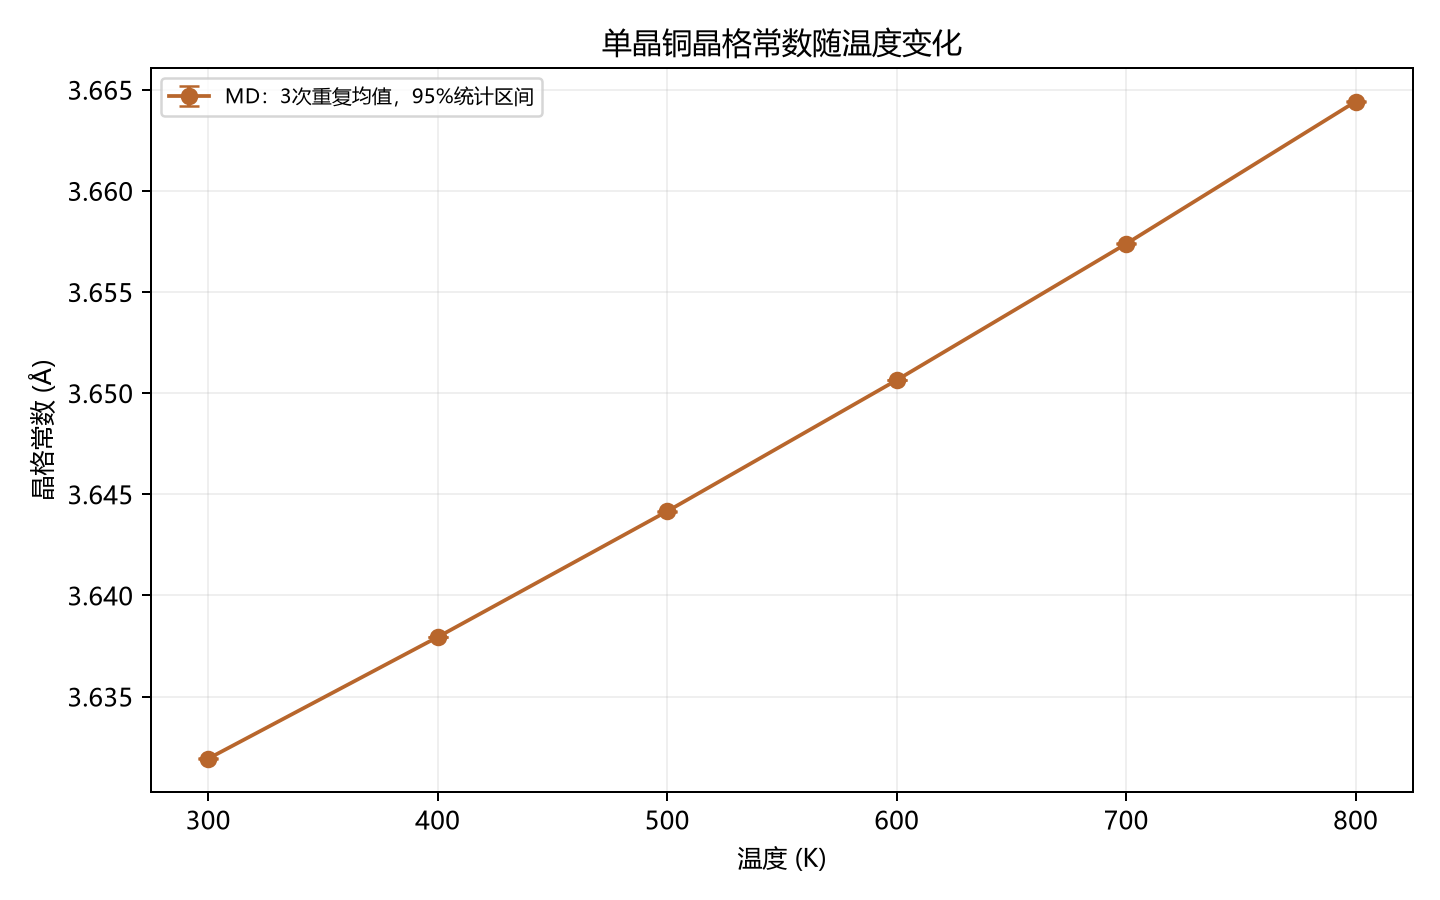

In [4]:
display(Image(filename='results/figures/lattice_temperature.png'))

图2 统一300 K参考后的线膨胀与体积变化

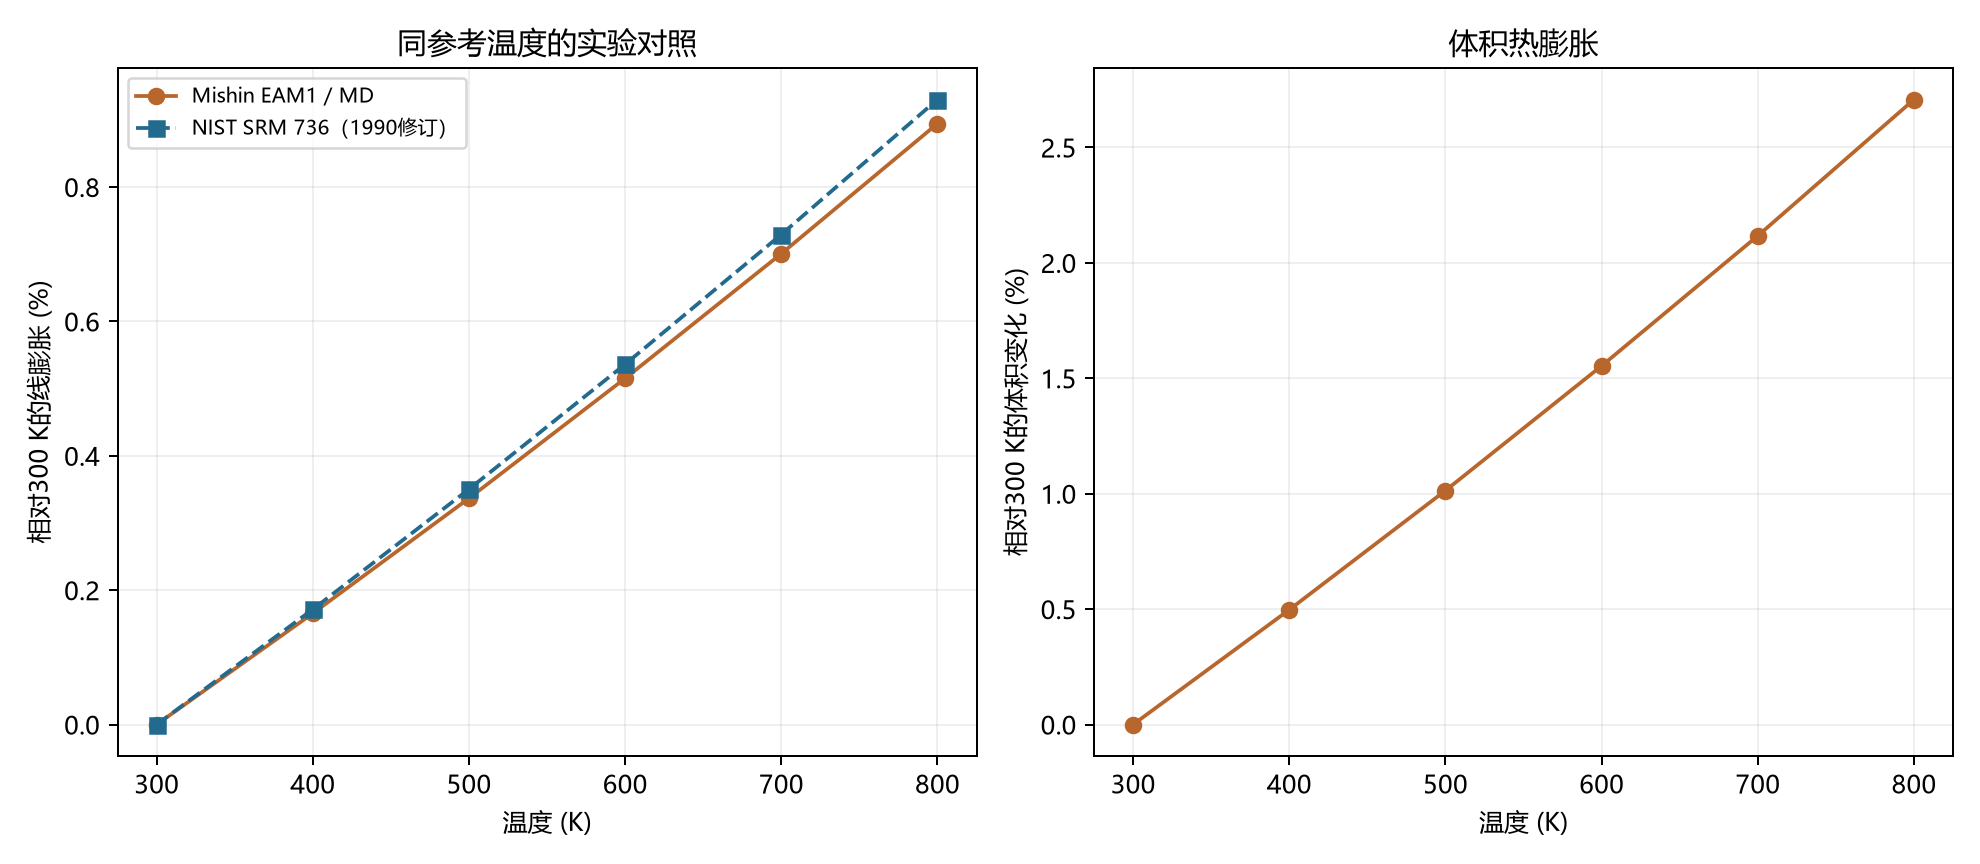

In [5]:
display(Image(filename='results/figures/expansion_comparison.png'))

图3 同定义温区平均系数对照

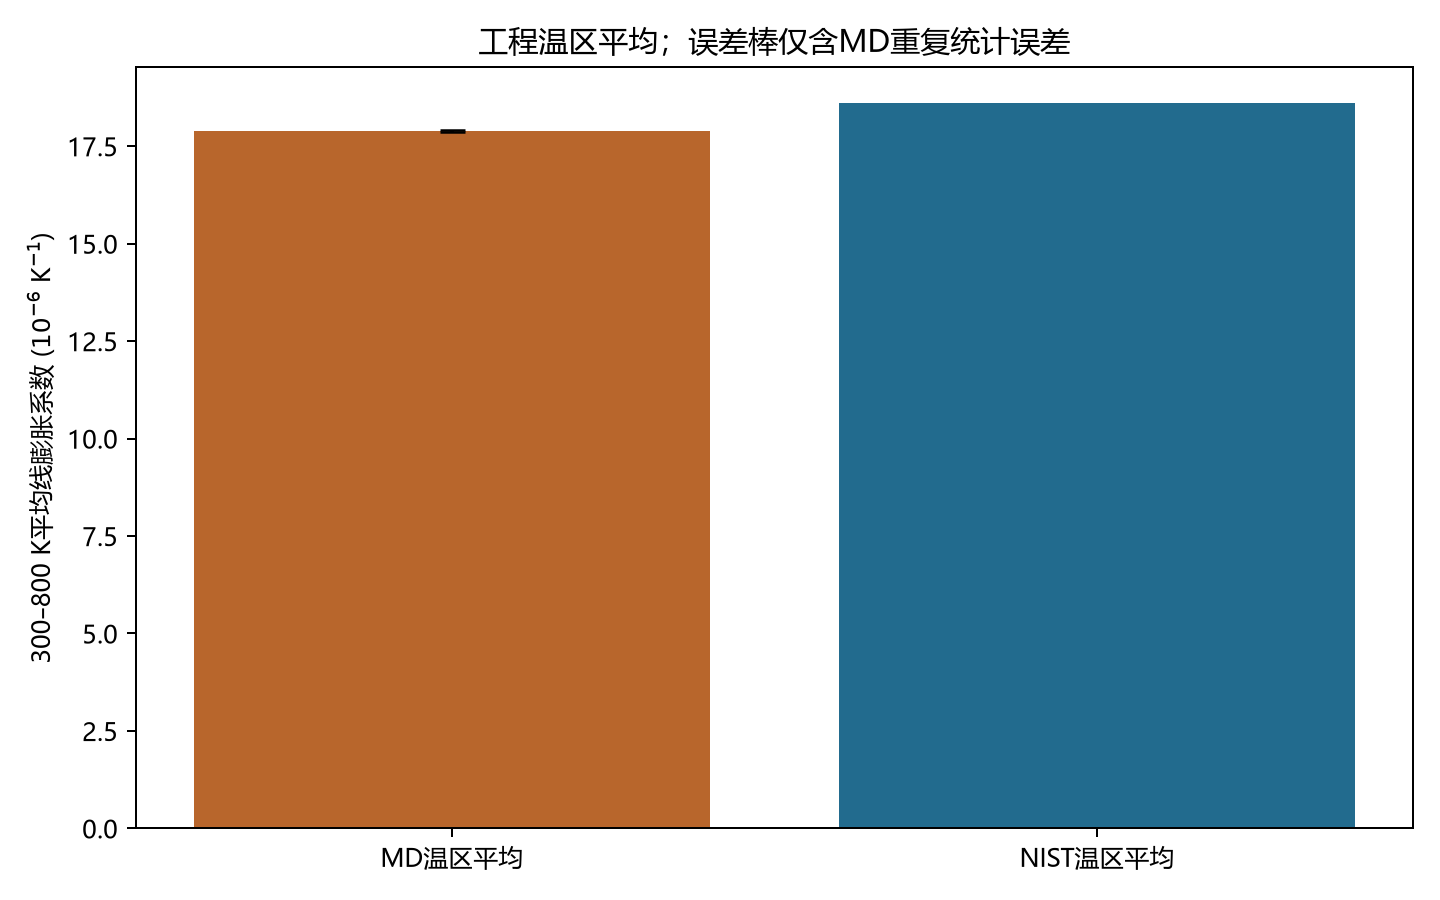

In [6]:
display(Image(filename='results/figures/alpha_comparison.png'))

图4 300 K温度、压力、能量、体积轨迹

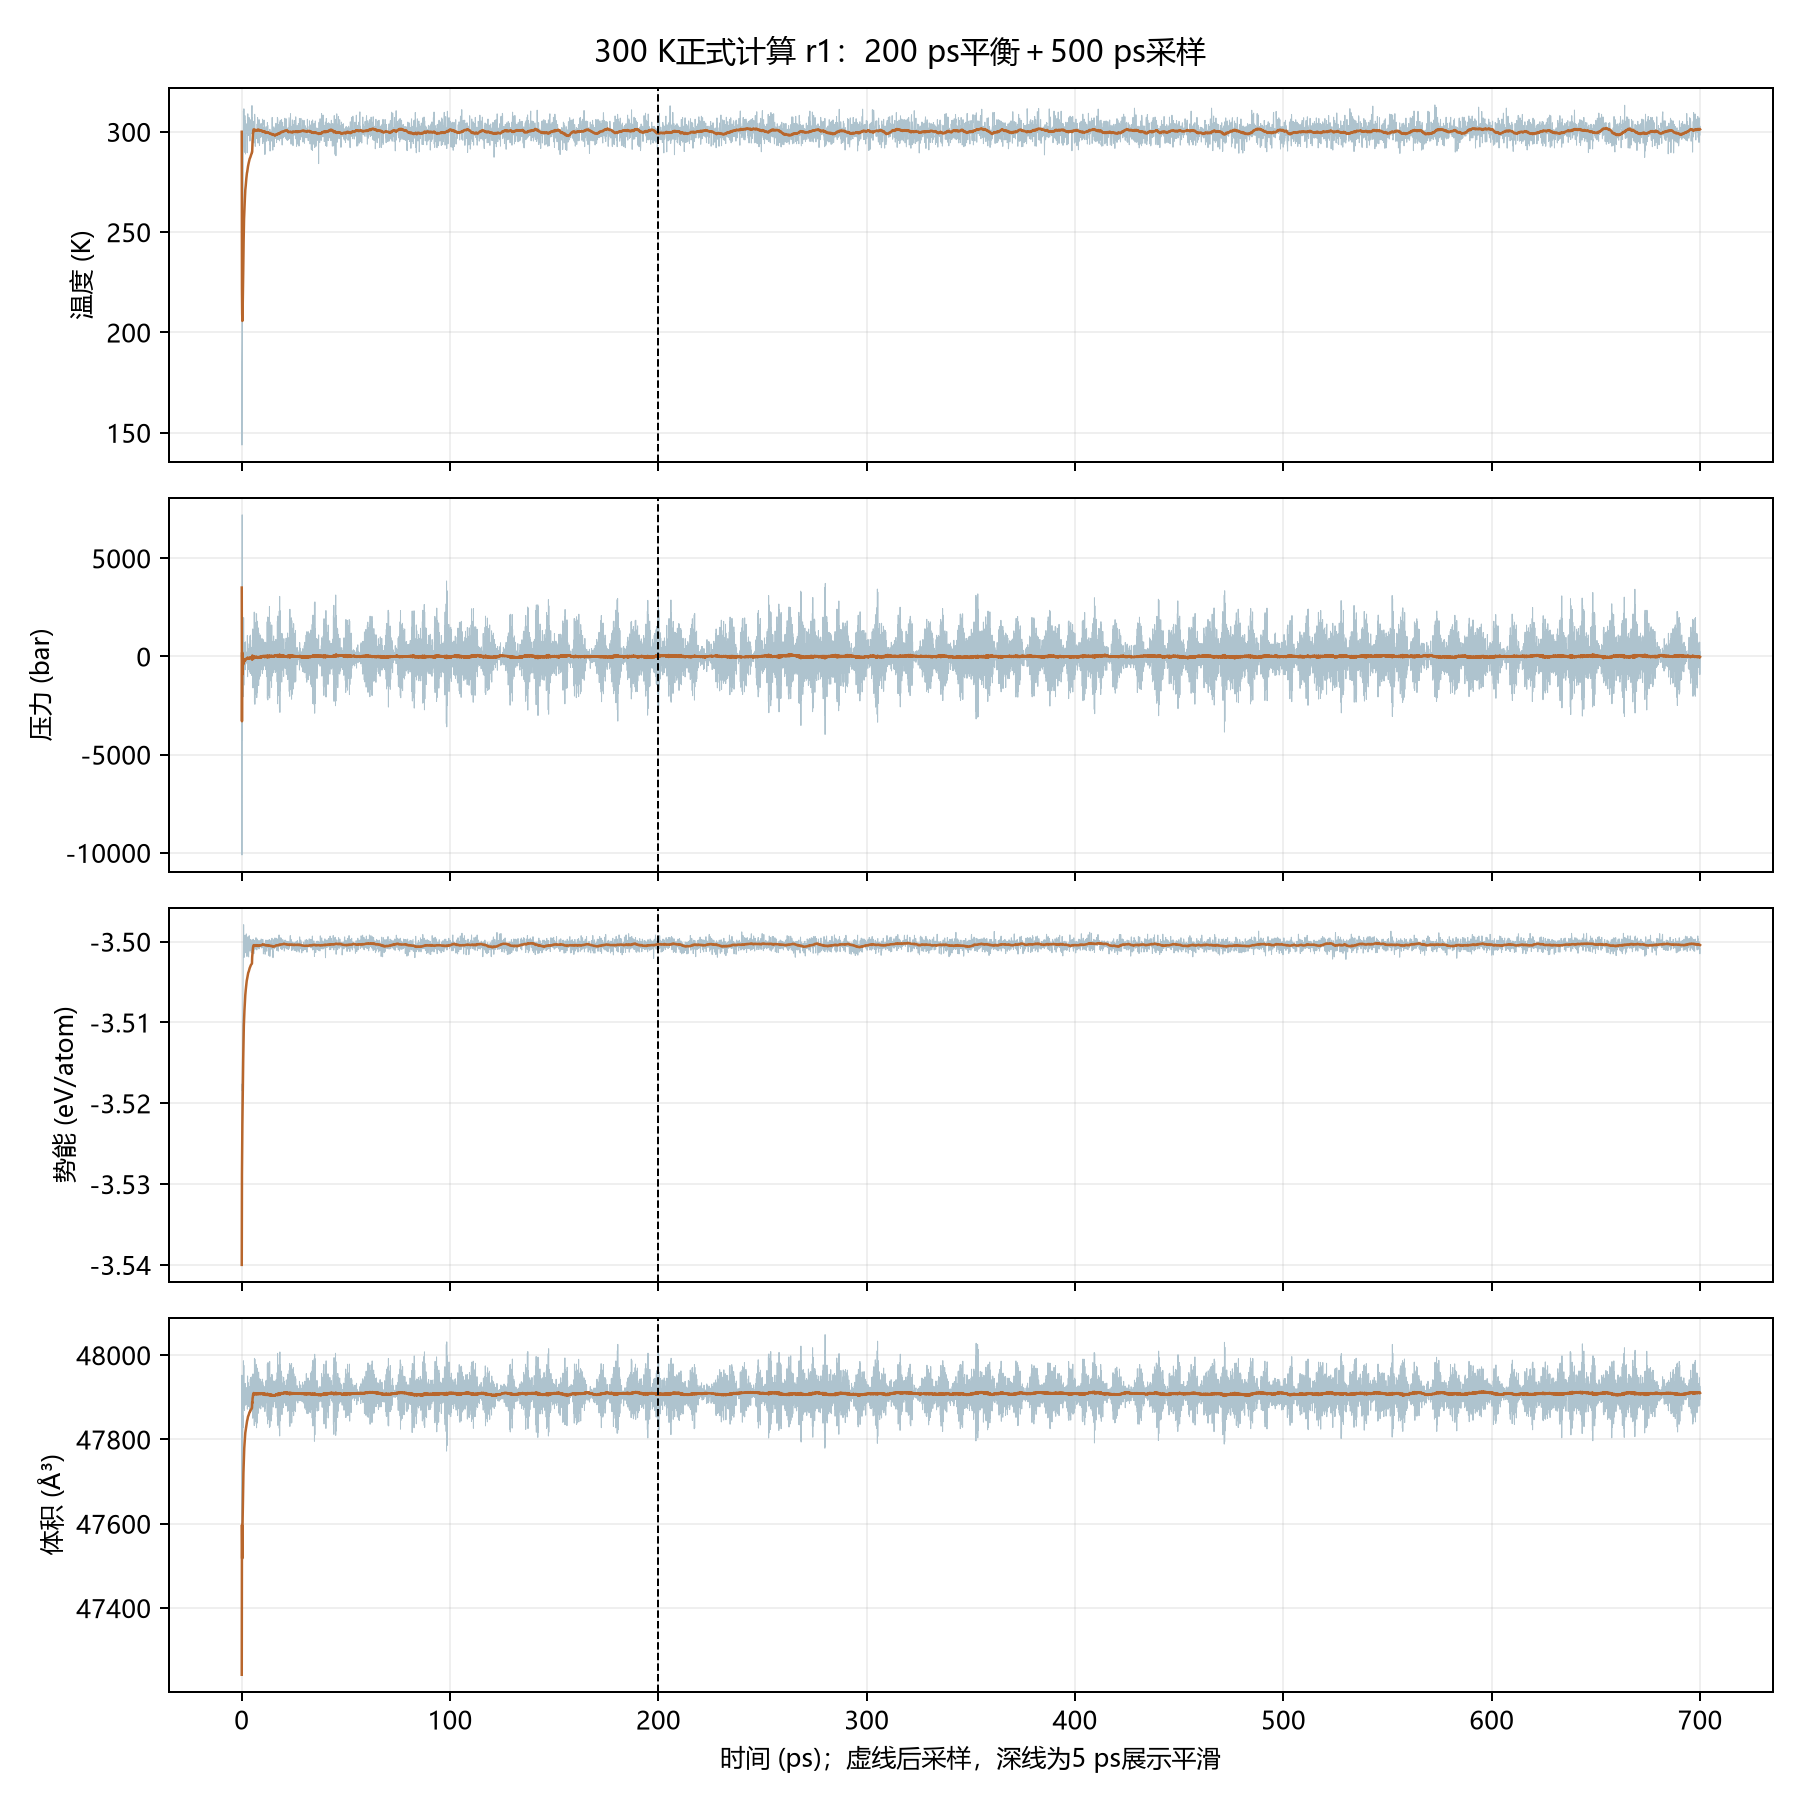

In [7]:
display(Image(filename='results/figures/equilibration_300.png'))

图5 800 K对应轨迹

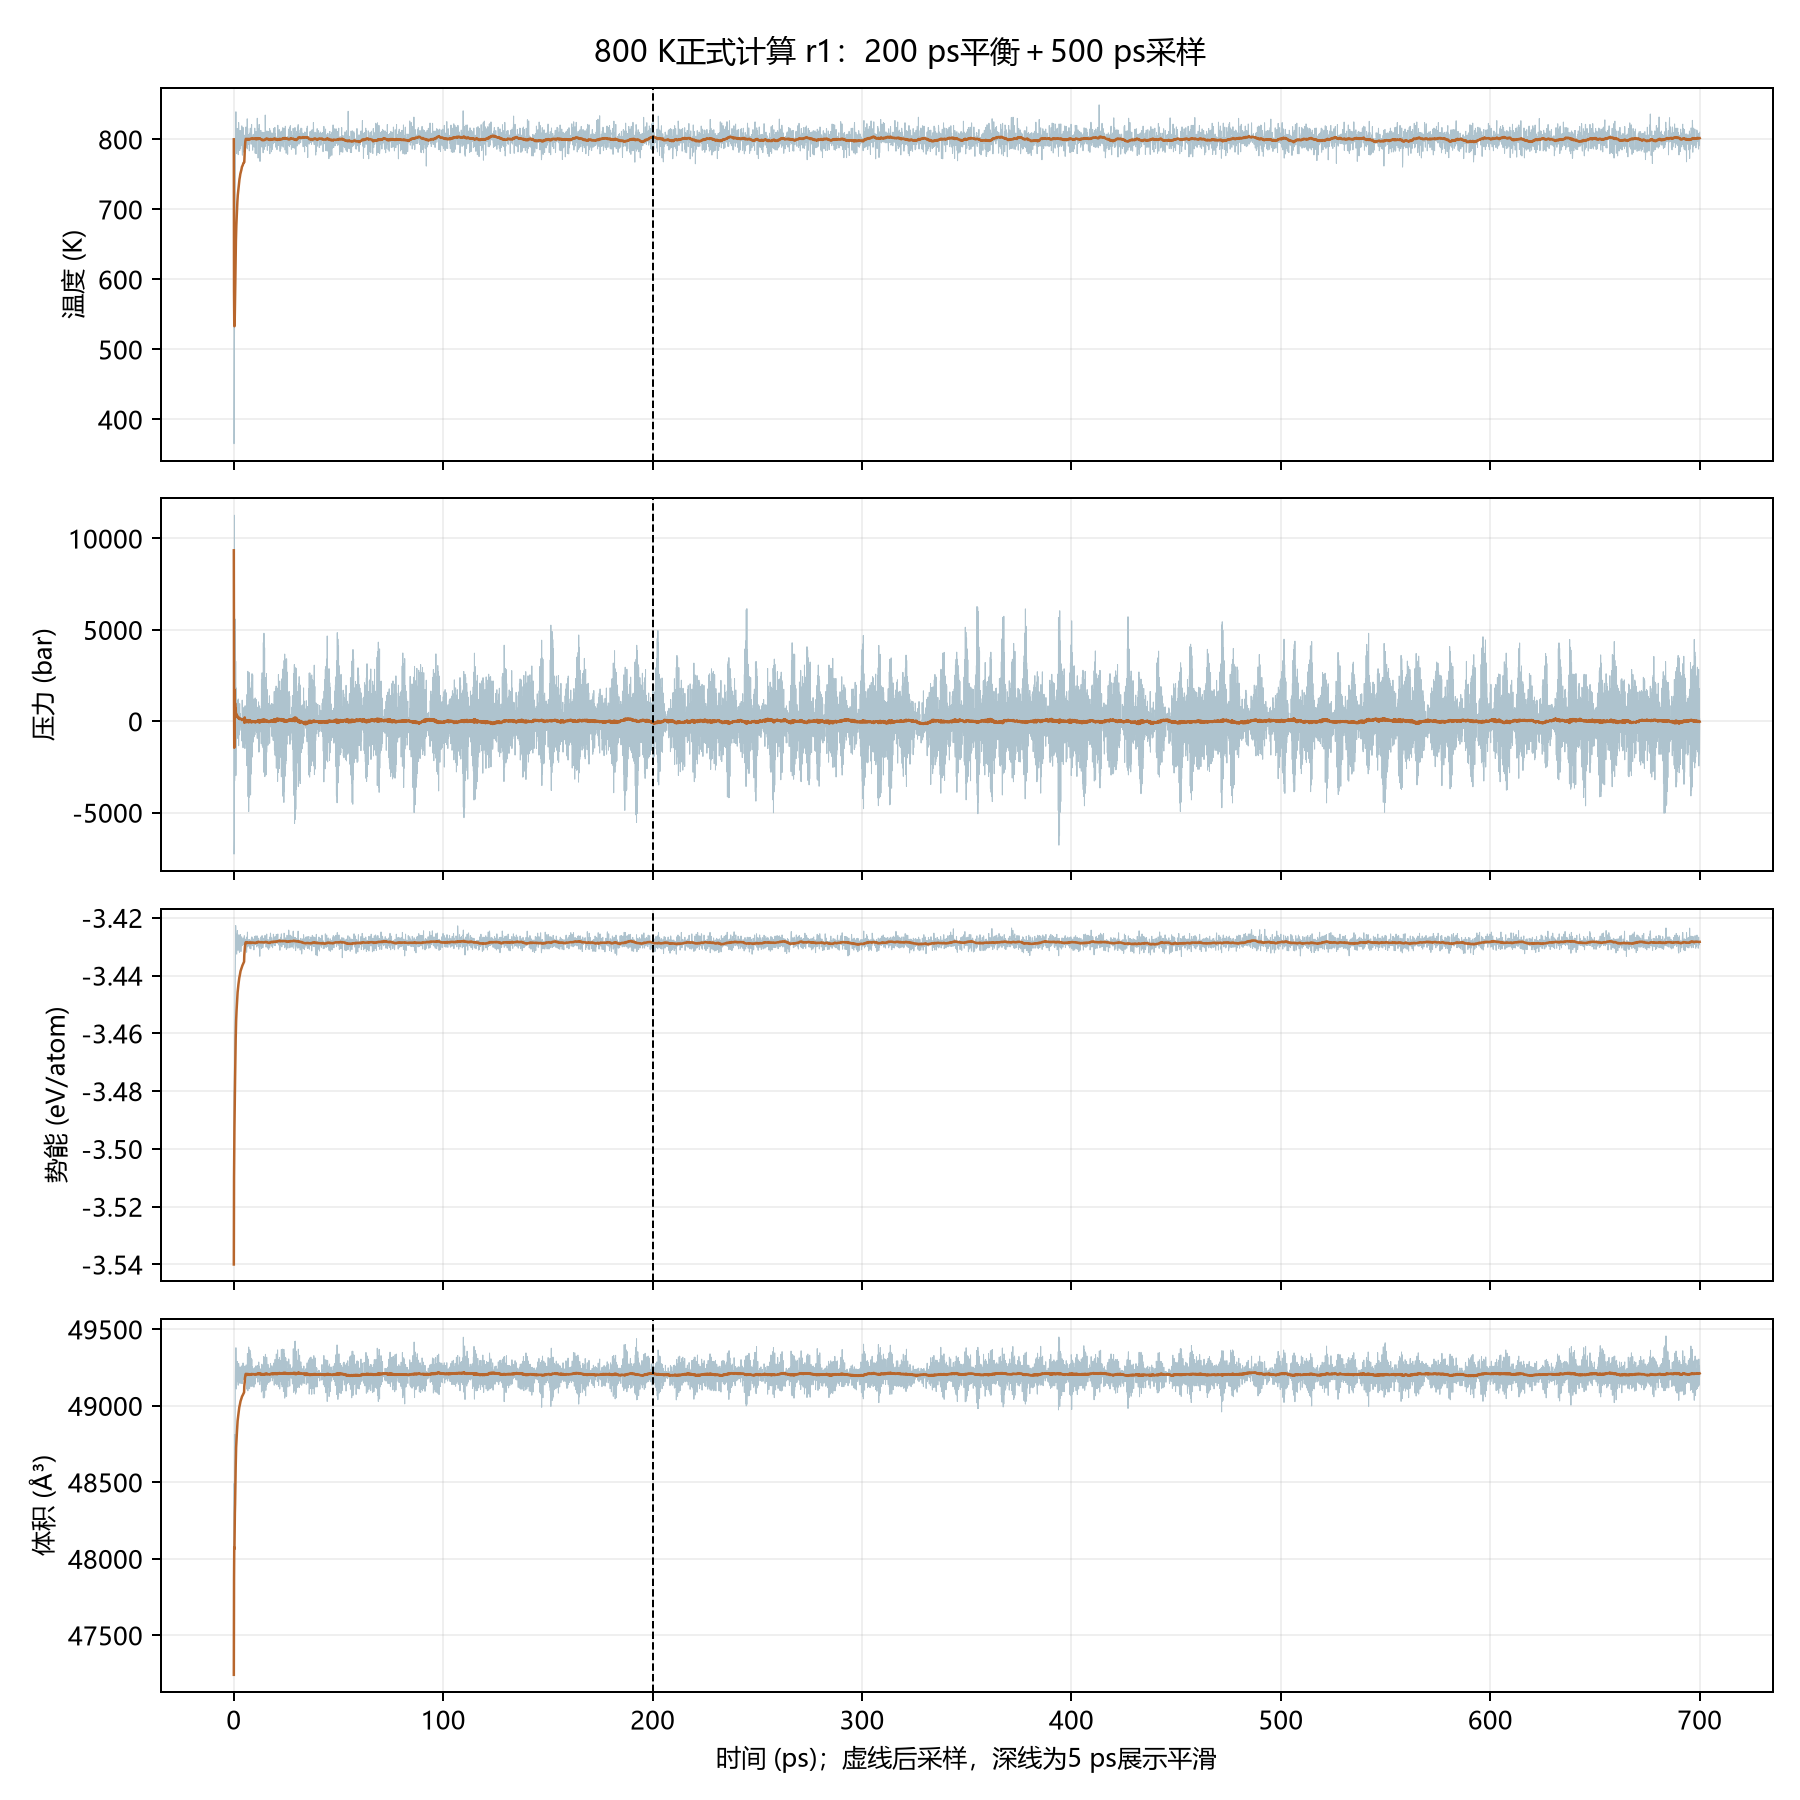

In [8]:
display(Image(filename='results/figures/equilibration_800.png'))

图6 分块长度敏感性

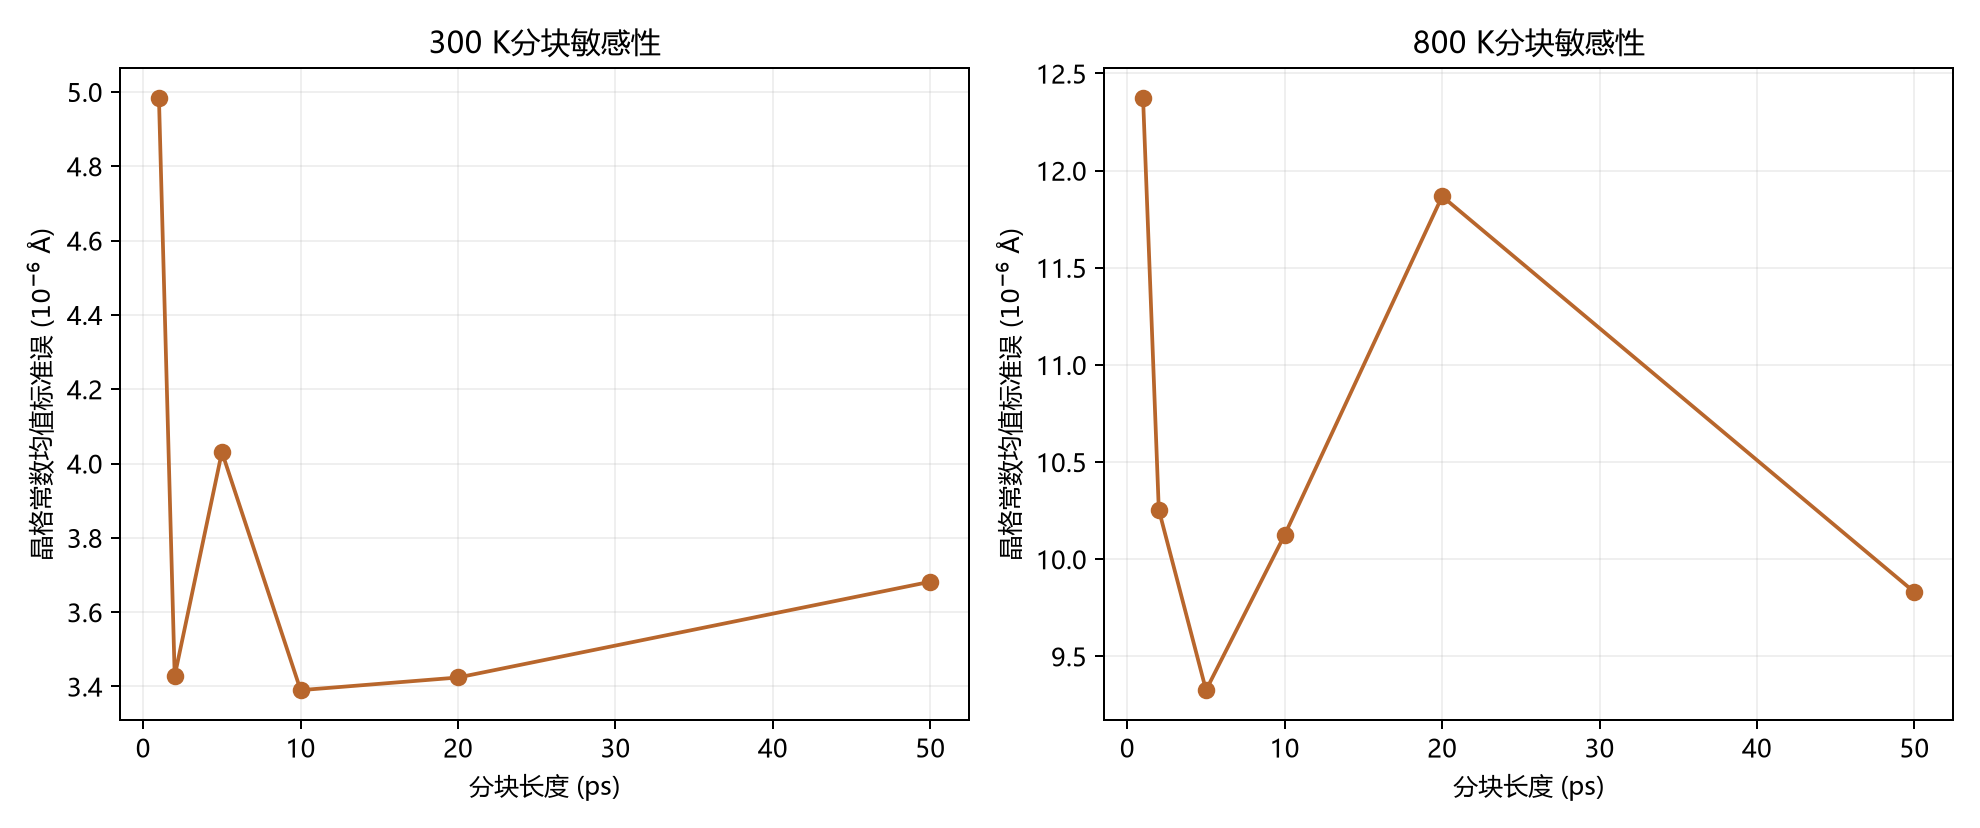

In [9]:
display(Image(filename='results/figures/block_sensitivity.png'))

图7 尺寸、步长、时长检查

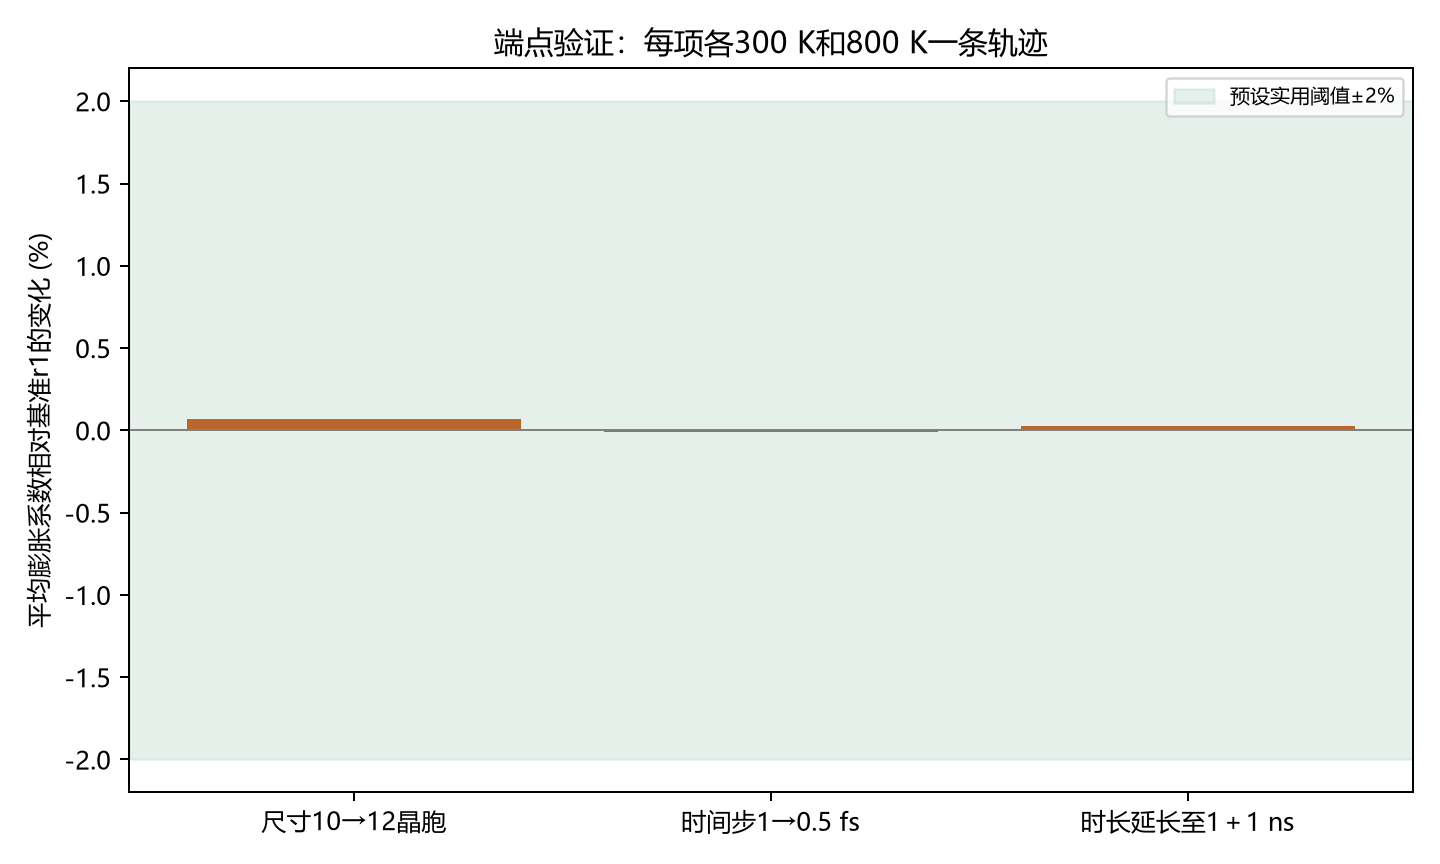

In [10]:
display(Image(filename='results/figures/validation.png'))

## 4. 讨论

20 ps增至50 ps分块时，均值标准误比值的中位数为1.018，范围为0.564–1.299，没有所有轨迹一致增长的现象。块数减少也会使误差估计自身波动，因此不能把单条曲线的局部平台看作严格证明。最终统计区间主要来自3次独立重复，自由度仅为2。

端点平均系数的三项参数敏感性远小于当前约3.85%的实验偏差，表明在已检查范围内，单纯改变这些数值参数不足以消除实验差异。这支持进一步关注势函数适用性及物理模型差别，但不构成对误差来源的唯一归因。

尺寸、步长和时长检查只针对300与800 K，中间温度没有完整扫描。Mishin EAM1的拟合目标、经典原子统计、理想晶体与真实试样的区别均可能产生偏差；本研究没有计算各因素的单独贡献。统计误差棒没有包含实验不确定度、势函数系统误差和经典近似误差。

本项目没有自行运行DFT、机器学习势或第二种EAM势。文献横向比较是方法与既有证据的比较，不能将其写成我们统一协议下跑出的势函数精度排行榜。

## 5. 结论

当前协议得到300–800 K平均线膨胀系数17.8883×10⁻⁶ K⁻¹，相对NIST参考偏差-3.85%。该结果针对Mishin EAM1、近零压、周期理想单晶及本项目温区，不推广到晶界、自由表面、熔化或其他势。可复现实验文件和全部统计表随仓库提供。

## 参考文献与复现

完整参考文献和横向方法比较见[文献调研](docs/literature_review.md)，势文件说明见[来源](potentials/SOURCE.md)。运行步骤、目录树及未完成事项见[README](README.md)。Notebook只读取结果和展示图，不在打开时自动启动数小时的模拟。

### 计算中断与数据核查说明

两条0.5 fs验证在中断后从200 ps平衡重启点重新连续采满500 ps，中断的采样后缀没有混入结果。重启边界自动输出的200 ps行与原前缀重复，严格检查确认只有这一处重复且值一致后移除，原始文件与修复前metadata均保留。该点不在大于200 ps的正式采样区间，清理不改变生产样本。检查同时核对最终重启点为1400000步、700 ps、4000原子。详见[恢复记录](docs/recovery_record.md)。